In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error 
from sklearn.model_selection import (KFold, cross_validate, cross_val_predict, train_test_split)
from scipy.stats import spearmanr
import shap
import time

TARGET = "peak_cell_floodable_area_m2" # "10cm_area"
GROUP_COL = None          # e.g. "catchment_id" / "cell_id" -- STRONGLY recommended if spatial/temporal autocorrelation
SEED = 42

from PrepDataFunctions import *
from ModelEvaluationFunctions import *

import sys, importlib
importlib.reload(sys.modules['ModelEvaluationFunctions'])
from ModelEvaluationFunctions import *

### Prepare data

In [2]:
df = prep_for_modelling(f"/scratch/hydro4/users/kv25483/FutureFlood/Data/EventDetails_v4/all_catchments.pkl", 
                        remove_events_with_zero_flooding = False)
print(len(df))
df = df[df['rainpeak_sm_day_before_onset'].notna()]
print(len(df))

df.rename(columns = {'dry_ratio_n':'dry_ratio'}, inplace=True)

subset_early = create_temporal_subset(df, "before", 2020).copy()

105589
105580


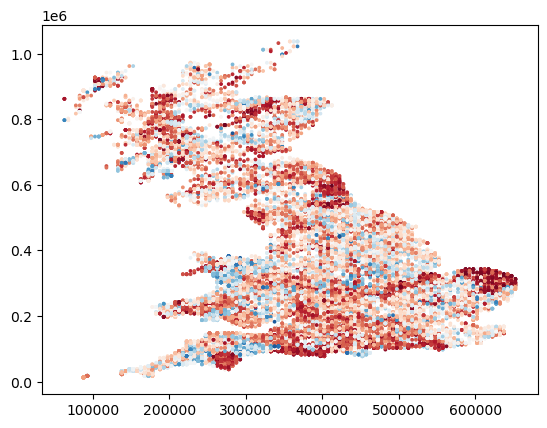

In [13]:
XCOL, YCOL = "rainpeak_x_coord", "rainpeak_y_coord"

# Coordinates for exactly the rows in `grouped`, in the same order
xy = subset_early.loc[subset_early.index, [XCOL, YCOL]].to_numpy()

# All drivers, each with its own colour scale (shows the spatial pattern of every driver)
# plot_shap_maps(grouped, xy)

fig, ax = plt.subplots()
v=subset_early['peak_cell_slope_max']
sc = ax.scatter(xy[:, 0], xy[:, 1], c=v, s=3, cmap='RdBu')

In [ ]:
def plot_shap_maps(grouped, xy, cols=None, ncols=3, pct=98, s=3, cmap="RdBu_r",
                   shared_scale=False, figsize_per_panel=(4.2, 4)):
    """One map per driver, coloured by its SHAP contribution (diverging, centred on 0)."""
    cols = list(cols) if cols is not None else list(grouped.columns)
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols,
                             figsize=(figsize_per_panel[0] * ncols, figsize_per_panel[1] * nrows),
                             squeeze=False)

    if shared_scale:
        lim_shared = np.nanpercentile(np.abs(grouped[cols].to_numpy()), pct)

    for ax, col in zip(axes.ravel(), cols):
        v = grouped[col].to_numpy()
        lim = lim_shared if shared_scale else np.nanpercentile(np.abs(v), pct)
        sc = ax.scatter(xy[:, 0], xy[:, 1], c=v, s=s, cmap=cmap, vmin=-lim, vmax=lim)
        ax.set_title(col)
        ax.set_aspect("equal")
        ax.set_xticks([]); ax.set_yticks([])
        plt.colorbar(sc, ax=ax, shrink=0.8, label="SHAP")

    for ax in axes.ravel()[len(cols):]:      # hide unused panels
        ax.axis("off")

    plt.tight_layout()
    plt.show()
    
plot_shap_maps    